[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_stormTracks_KKN_May2024_HID_doppler/blob/main/notebooks/02_cappi_echo_objects_month.ipynb)


# บทที่ 02 — จาก CAPPI สู่วัตถุพายุ: ภาพรวมทั้งเดือน

บทที่ 01 บอกว่า **รายงานความเสียหาย** เกิดวันไหน ที่ไหน บทนี้ถามคำถามเดียวกันกับ **เรดาร์** ซึ่งเห็นพายุทุกลูก ไม่ว่าจะสร้างความเสียหายหรือไม่ เราจะเริ่มจากภาพ pseudo-CAPPI 2 km แล้วนิยาม "วัตถุพายุ" (echo object) ซึ่งเป็นพื้นฐานของการติดตามพายุในบท 03

### วัตถุประสงค์การเรียนรู้
1. อธิบายหลักการ pseudo-CAPPI และอ่านแผนที่ความสูงของข้อมูลที่ใช้จริง (`source_height_m`) เพื่อรู้ข้อจำกัดใกล้และไกลเรดาร์
2. นิยามวัตถุพายุด้วยค่าขีดแบ่ง reflectivity และ connected components คำนวณพื้นที่และเส้นผ่านศูนย์กลางเทียบเท่า
3. สรุปพื้นที่ echo ทั้งเดือนเป็นปฏิทินพายุและวัฏจักรรายวัน แยกตามช่วงของเดือน
4. ทดสอบว่าวันที่มีรายงานความเสียหายมี echo รุนแรงมากกว่าวันที่ไม่มีรายงานหรือไม่ โดยใช้ "วัน" เป็นหน่วยวิเคราะห์
5. อ่านแผนที่ความถี่ของ echo ทั้งเดือนอย่างระมัดระวัง (ผลของระยะเรดาร์)

**ข้อมูล:** `data/derived/volume_stats_p1.csv` (สถิติทุก volume ทั้งเดือน), `monthly_summary_1km.nc`, กริดรายวันของวันหลักใน `data/days/`

In [1]:
# @title ⚙️ เตรียมสภาพแวดล้อม (รันก่อนเสมอ)
import os, sys, subprocess
REPO = "Teach_stormTracks_KKN_May2024_HID_doppler"
if "google.colab" in sys.modules:
    if not os.path.isdir(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", f"https://github.com/nattaponm/{REPO}.git", f"/content/{REPO}"], check=True)
    else:
        subprocess.run(["git", "-C", f"/content/{REPO}", "pull", "-q"])
    os.chdir(f"/content/{REPO}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) in ("notebooks", "prep"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("โฟลเดอร์ทำงาน:", os.getcwd(), "| CPU", os.cpu_count(), "core")

โฟลเดอร์ทำงาน: /content/Teach_stormTracks_KKN_May2024_HID_doppler | CPU 2 core


In [2]:
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats, ndimage
warnings.filterwarnings("ignore")

from utils.config import load_settings, repo_path
from utils import maps as M, geo as G, data as D, analysis as A, track_tools as tt
s = load_settings()
M.setup_style()
pd.set_option("display.width", 200, "display.max_columns", 30)
DEM = G.load_dem(s)                                   # (array, extent) — สร้างจาก Copernicus ครั้งแรกถ้ายังไม่มี
idx = D.day_index()
KEY_DAYS = list(idx.loc[idx["in_repo"], "day"]) if len(idx) else [pd.Timestamp("2024-05-03")]
KEY = KEY_DAYS[0]                                     # วันหลักที่มีกริดใน repo (เปลี่ยนเป็นวันอื่นได้ จะดาวน์โหลดจาก Zenodo)
print("วันหลักใน repo:", [f"{d:%d %b}" for d in KEY_DAYS], "| ใช้วัน:", f"{KEY:%d %b %Y}")

วันหลักใน repo: ['03 May', '05 May', '06 May', '22 May'] | ใช้วัน: 03 May 2024


## 1. pseudo-CAPPI 2 km คืออะไร และเชื่อได้แค่ไหน

เรดาร์ KKN สแกน 4 มุมยก (0.5°, 1.5°, 2.4°, 3.4°) ข้อมูลแต่ละมุมอยู่สูงต่างกันตามระยะ **CAPPI** (Constant Altitude PPI) คือภาพที่ความสูงคงที่ ทำได้โดยประมาณค่าระหว่างมุมยกสองมุมที่คร่อมความสูงเป้าหมาย $h^*$ = 2 km ในหน่วย Z เชิงเส้น

$$Z(h^*) = (1-w)\,Z_{\text{lo}} + w\,Z_{\text{hi}}, \qquad w = \frac{h^*-h_{\text{lo}}}{h_{\text{hi}}-h_{\text{lo}}}, \qquad \text{dBZ} = 10\log_{10} Z$$

"pseudo" หมายถึง ใกล้เรดาร์ (< ~30 km) แม้มุมสูงสุดก็ยังต่ำกว่า 2 km จึงใช้มุมสูงสุด ส่วนไกลเรดาร์ (> ~90 km) มุมต่ำสุดสูงกว่า 2 km จึงใช้มุมต่ำสุด ความสูงที่ใช้จริงเก็บไว้ใน `source_height_m`

**Z สูงสุดในคอลัมน์** (column-max) คือค่าสูงสุดของทุกมุมยกเหนือ pixel นั้น — บอกความแรงของแกนพายุได้ดีกว่า แต่ไม่ได้อยู่ที่ความสูงเดียวกันทุก pixel

In [3]:
Z, meta = D.load_cappi(KEY)
times = pd.to_datetime(meta["timestamps"])
with xr.open_dataset(D.day_file(KEY, "cappi_15min")) as ds:
    ZC = ds["zmax_column"].values[:, ::-1]                # พลิกให้แถวแรกเป็นทิศเหนือเหมือน Z
area35 = np.array([np.nansum(z >= 35) for z in Z])
it = int(np.nanargmax(area35))
print(f"เวลาที่มีพื้นที่ ≥ 35 dBZ มากที่สุด: {times[it]:%H:%M} UTC ({times[it] + pd.Timedelta(hours=7):%H:%M} น.) = {area35[it]:.0f} km²")

เวลาที่มีพื้นที่ ≥ 35 dBZ มากที่สุด: 10:00 UTC (17:00 น.) = 1385 km²


บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb02_cappi_colmax_height.png / .pdf


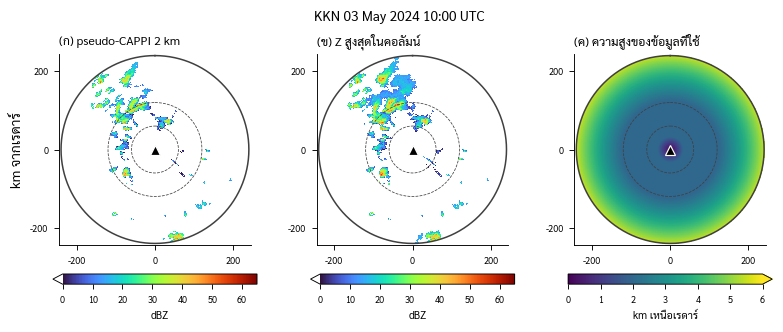

In [4]:
cm, nm = plt.get_cmap("turbo").copy(), plt.Normalize(0, 65)
cm.set_under("white")
fig, axs = plt.subplots(1, 3, figsize=(7.2, 2.9), layout="constrained")
panels = [(Z[it], "(ก) pseudo-CAPPI 2 km", cm, nm, "dBZ"), (ZC[it], "(ข) Z สูงสุดในคอลัมน์", cm, nm, "dBZ"),
          (meta["source_height_m"] / 1000, "(ค) ความสูงของข้อมูลที่ใช้", plt.get_cmap("viridis"), plt.Normalize(0, 6), "km เหนือเรดาร์")]
for ax, (g, ttl, c, n, lab) in zip(axs, panels):
    im = A.show_grid(ax, g, meta, cmap=c, norm=n)
    M.add_range_rings(ax, s, rings_km=[60, 120, 240], label=False, name=False)
    ax.set_xlim(-245, 245); ax.set_ylim(-245, 245); ax.set_aspect("equal")
    ax.set_xticks([-200, 0, 200]); ax.set_yticks([-200, 0, 200]); ax.tick_params(labelsize=6)
    ax.set_title(ttl, loc="left", fontsize=8)
    cb = fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.85, pad=0.04, extend="min" if lab == "dBZ" else "max")
    cb.set_label(lab, fontsize=7); cb.ax.tick_params(labelsize=6)
axs[0].set_ylabel("km จากเรดาร์")
fig.suptitle(f"KKN {times[it]:%d %b %Y %H:%M} UTC", fontsize=9)
M.savefig(fig, "nb02_cappi_colmax_height")
plt.show()

**อ่านรูป:** ในรูป (ค) วงในสุด (< ~30 km) ใช้มุมยกสูงสุดซึ่งยังต่ำกว่า 2 km และนอก ~90 km ความสูงของข้อมูลเพิ่มขึ้นตามระยะจนเกิน 5 km ที่ขอบ ดังนั้น "35 dBZ ที่ 200 km" ไม่ใช่สิ่งเดียวกับ "35 dBZ ที่ 50 km" — ข้อนี้จะกลับมาเป็นตัวแปรแทรกซ้อนในบท 04–06

## 2. วัตถุพายุ (echo object)

นิยามวัตถุพายุ = กลุ่ม pixel ที่ติดกัน (8 ทิศ) ซึ่ง $Z \ge Z_{\text{th}}$ และมีขนาดอย่างน้อย $N_{\min}$ pixel

$$A = N_{\text{pixel}} \times 1\ \text{km}^2, \qquad D_{\text{eq}} = 2\sqrt{A/\pi}$$

T-DaTing ในบท 03 ใช้แนวคิดเดียวกันแต่ซับซ้อนกว่า (แยกแกนที่อยู่ติดกันด้วย `mindiff` และต้องมีค่าสูงสุด ≥ `minmax`) ที่นี่เริ่มจากแบบง่ายก่อน

In [5]:
def echo_objects(z, thr=35.0, min_px=15):
    lab, n = ndimage.label(np.nan_to_num(z, nan=-99) >= thr, structure=np.ones((3, 3)))
    size = ndimage.sum(np.ones_like(lab), lab, index=np.arange(1, n + 1))
    keep = np.where(size >= min_px)[0] + 1
    lab = np.where(np.isin(lab, keep), lab, 0)
    rows = []
    for k in keep:
        m = lab == k
        rows.append({"id": int(k), "area_km2": int(m.sum()), "Deq_km": 2 * np.sqrt(m.sum() / np.pi), "Zmax": float(np.nanmax(z[m]))})
    return lab, pd.DataFrame(rows)

lab35, obj35 = echo_objects(Z[it], 35)
lab45, obj45 = echo_objects(Z[it], 45, 5)
print(f"35 dBZ: {len(obj35)} วัตถุ, D_eq มัธยฐาน {obj35['Deq_km'].median():.1f} km | 45 dBZ (แกน): {len(obj45)} วัตถุ")
obj35.sort_values("area_km2", ascending=False).head(8).round(1)

35 dBZ: 14 วัตถุ, D_eq มัธยฐาน 10.2 km | 45 dBZ (แกน): 7 วัตถุ


,id,area_km2,Deq_km,Zmax
13,38,263,18.3,52.5
0,1,149,13.8,45.5
12,31,147,13.7,48.6
4,11,115,12.1,47.5
7,16,114,12.0,48.6
5,13,86,10.5,47.5
3,9,83,10.3,42.0
9,22,82,10.2,45.5


บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb02_echo_objects.png / .pdf


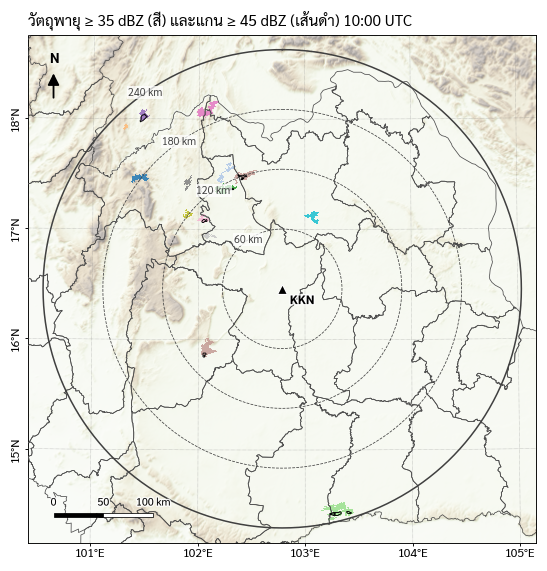

In [6]:
fig, ax = plt.subplots(figsize=(6.0, 6.0))
M.base_map(ax, s, dem=DEM, dem_alpha=0.5, province_labels=False)
rng = np.random.default_rng(3)
col = plt.get_cmap("tab20")(rng.permutation(20))
L = np.where(lab35 > 0, lab35 % 20, np.nan)
A.show_grid(ax, L, meta, cmap=plt.matplotlib.colors.ListedColormap(col), vmin=0, vmax=19, zorder=8, alpha=0.85)
ax.contour(meta["x"] / 1e3, meta["y"] / 1e3, (lab45 > 0).astype(float), levels=[0.5], colors="k", linewidths=0.6, zorder=10)
ax.set_title(f"วัตถุพายุ ≥ 35 dBZ (สี) และแกน ≥ 45 dBZ (เส้นดำ) {times[it]:%H:%M} UTC", loc="left")
M.savefig(fig, "nb02_echo_objects")
plt.show()

## 3. ปฏิทินพายุทั้งเดือน และวัฏจักรรายวัน

`volume_stats_p1.csv` มีหนึ่งแถวต่อ volume (ทุก 15 นาที) พร้อมพื้นที่ pseudo-CAPPI ≥ 20, 30, 35, 40, 45, 50 dBZ เราสรุปเป็นรายวันและรายชั่วโมงท้องถิ่น

**ทำไมต้องรายวัน:** volume ติดกันเห็นพายุลูกเดียวกัน จึงไม่เป็นอิสระต่อกัน และพายุทั้งวันเกิดจากบรรยากาศชุดเดียวกัน หน่วยที่เป็นอิสระพอจะทดสอบสถิติคือ "วัน"

In [7]:
st = D.table("volume_stats_p1.csv")
st = st[st["status"] == "ok"].copy()
st["day"] = st["slot_utc"].dt.normalize()
st["hour_local"] = (st["slot_utc"] + pd.Timedelta(hours=7)).dt.hour
st = A.add_phase(st)
daily = st.groupby("day").agg(n_vol=("slot_utc", "size"), max_A35=("area_ge35_km2", "max"), max_A45=("area_ge45_km2", "max"),
                              sum_A35_h=("area_ge35_km2", lambda a: a.sum() * 0.25), Zmax=("col_max_dbz", "max"))
rep_days = pd.read_csv(repo_path("data", "reports", "days_may2024.csv"), parse_dates=["date"]).set_index("date")
daily["has_report"] = daily.index.isin(rep_days.index[rep_days["n_in_range"] > 0])
daily = A.add_phase(daily.reset_index())
daily.round(0)

,day,n_vol,max_A35,max_A45,sum_A35_h,Zmax,has_report,phase
0,2024-05-01,96,275.0,27.0,1322.0,56.0,True,outbreak
1,2024-05-02,88,725.0,84.0,2780.0,52.0,True,outbreak
2,2024-05-03,92,1377.0,157.0,12184.0,60.0,True,outbreak
3,2024-05-04,96,1525.0,153.0,9046.0,60.0,True,outbreak
4,2024-05-05,96,1465.0,227.0,11786.0,58.0,True,outbreak
5,2024-05-06,96,3072.0,218.0,30898.0,58.0,True,outbreak
6,2024-05-07,96,1143.0,142.0,5929.0,58.0,False,outbreak
7,2024-05-08,96,1420.0,145.0,9435.0,56.0,False,outbreak
8,2024-05-09,96,1186.0,121.0,10404.0,62.0,False,outbreak
9,2024-05-10,96,2886.0,253.0,23189.0,60.0,False,late_pre


บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb02_calendar_diurnal.png / .pdf


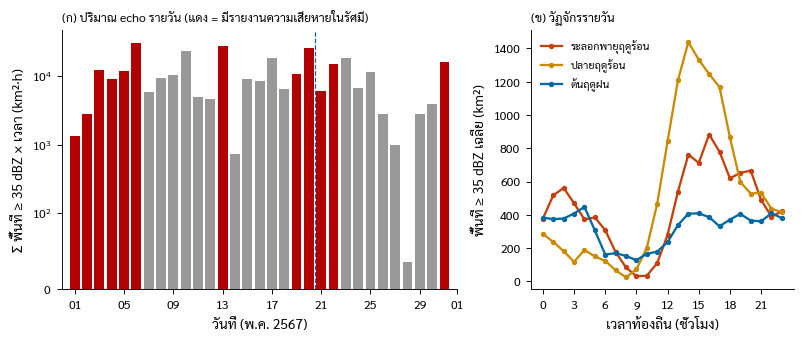

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(7.2, 3.0), gridspec_kw={"width_ratios": [1.5, 1]}, layout="constrained")
ax = axs[0]
ax.bar(daily["day"], daily["sum_A35_h"], color=np.where(daily["has_report"], "#b30000", "0.6"), width=0.8)
ax.set_yscale("symlog", linthresh=100); ax.set_ylabel("Σ พื้นที่ ≥ 35 dBZ × เวลา (km²·h)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d")); ax.set_xlabel("วันที่ (พ.ค. 2567)")
ax.set_xlim(pd.Timestamp("2024-04-30"), pd.Timestamp("2024-06-01"))
ax.axvline(pd.Timestamp("2024-05-20 12:00"), color="#0369a1", ls="--", lw=0.8)
ax.set_title("(ก) ปริมาณ echo รายวัน (แดง = มีรายงานความเสียหายในรัศมี)", loc="left", fontsize=8)
ax = axs[1]
for ph, g in st.groupby("phase", observed=True):
    med = g.groupby("hour_local")["area_ge35_km2"].mean()
    ax.plot(med.index, med.values, "-o", ms=2.5, color=M.PHASE_COLORS[ph], label=[p["label_th"] for p in s["phases"] if p["key"] == ph][0])
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("เวลาท้องถิ่น (ชั่วโมง)"); ax.set_ylabel("พื้นที่ ≥ 35 dBZ เฉลี่ย (km²)")
ax.legend(fontsize=7, frameon=False)
ax.set_title("(ข) วัฏจักรรายวัน", loc="left", fontsize=8)
M.savefig(fig, "nb02_calendar_diurnal")
plt.show()

## 4. วันที่มีรายงานความเสียหาย "แรงกว่า" จริงหรือไม่

สมมติฐาน: พื้นที่แกนพายุ (≥ 45 dBZ) สูงสุดรายวันของวันที่มีรายงาน > วันที่ไม่มีรายงาน ใช้ **Mann–Whitney U** (ไม่ต้องสมมติการแจกแจงปกติ) และขนาดผล **Cliff's δ**

$$\delta = P(X > Y) - P(X < Y), \qquad |\delta| < 0.147 \text{ เล็กมาก},\ < 0.33 \text{ เล็ก},\ < 0.474 \text{ ปานกลาง},\ \ge 0.474 \text{ ใหญ่}$$

หน่วยวิเคราะห์ = วัน (ไม่ใช่ volume) ถ้ามีข้อมูลน้อยกว่า 3 วันต่อกลุ่ม ผลจะไม่มีความหมาย โค้ดจะเตือน

In [9]:
a = daily.loc[daily["has_report"], "max_A45"]; b = daily.loc[~daily["has_report"], "max_A45"]
if min(len(a), len(b)) >= 3:
    u = stats.mannwhitneyu(a, b, alternative="greater")
    print(f"วันมีรายงาน n={len(a)} มัธยฐาน {a.median():.0f} km² | ไม่มีรายงาน n={len(b)} มัธยฐาน {b.median():.0f} km²")
    print(f"Mann–Whitney U = {u.statistic:.0f}, p (ด้านเดียว) = {u.pvalue:.3f}, Cliff's δ = {tt.cliffs_delta(a, b):.2f}")
else:
    print(f"ข้อมูลยังไม่พอ (มีรายงาน {len(a)} วัน, ไม่มี {len(b)} วัน) — ต้องมีอย่างน้อย 3 วันต่อกลุ่ม")

วันมีรายงาน n=12 มัธยฐาน 155 km² | ไม่มีรายงาน n=19 มัธยฐาน 91 km²
Mann–Whitney U = 148, p (ด้านเดียว) = 0.087, Cliff's δ = 0.30


## 5. ความถี่ของ echo ทั้งเดือน

$$f_{35}(x, y) = \frac{100}{N_{\text{obs}}}\sum_{t=1}^{N_{\text{obs}}} \mathbb{1}\!\left[Z_t(x,y) \ge 35\right] \quad (\%)$$

หารด้วยจำนวน volume ที่ **มีข้อมูลจริง** ($N_{\text{obs}}$) ไม่ใช่ 96 × 31 เพื่อไม่ให้วันที่ข้อมูลขาดดูเหมือนไม่มีพายุ

บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb02_echo_frequency.png / .pdf


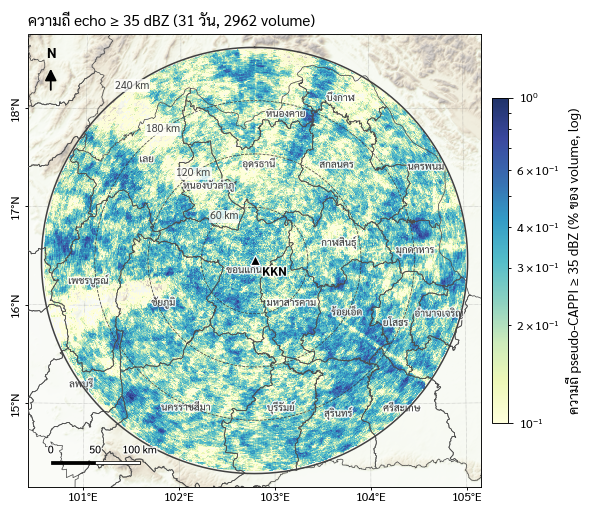

In [10]:
with xr.open_dataset(repo_path("data", "derived", "monthly_summary_1km.nc")) as ms:
    MS = {k: ms[k].values for k in ms.data_vars}
    days_in = ms.attrs.get("days", "")
fig, ax = plt.subplots(figsize=(6.4, 6.4))
M.base_map(ax, s, dem=DEM, dem_alpha=0.45)
f = np.where(MS["freq_ge35_pct"] > 0, MS["freq_ge35_pct"], np.nan)
im = A.show_grid(ax, f, meta, cmap="YlGnBu", norm=plt.matplotlib.colors.LogNorm(0.1, max(np.nanmax(f), 1)), zorder=8, alpha=0.9)
fig.colorbar(im, ax=ax, shrink=0.6, pad=0.02, label="ความถี่ pseudo-CAPPI ≥ 35 dBZ (% ของ volume, log)")
ax.set_title(f"ความถี่ echo ≥ 35 dBZ ({len(days_in.split(','))} วัน, {int(np.nanmax(MS['n_obs_total']))} volume)", loc="left")
M.savefig(fig, "nb02_echo_frequency")
plt.show()

## 6. แบบฝึกหัด

**ข้อ 1** นับวัตถุพายุทุกเวลาของวันหลักที่ค่าขีดแบ่ง 35 และ 40 dBZ (ขนาด ≥ 15 pixel) แล้ววาดอนุกรมเวลาของจำนวนวัตถุ ค่าขีดแบ่งที่สูงขึ้นทำให้ "จำนวน" วัตถุเพิ่มหรือลดในช่วงพายุแรง เพราะอะไร

In [11]:
# เขียนโค้ดของตนเองที่นี่

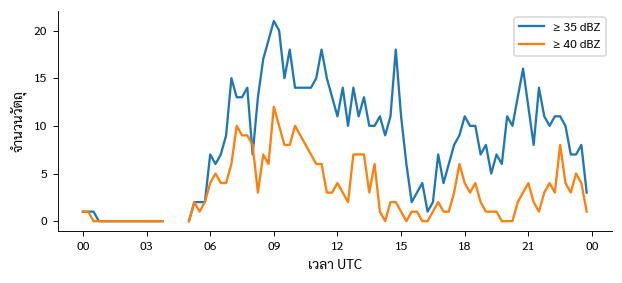

In [12]:
# @title เฉลยข้อ 1
cnt = {thr: [len(echo_objects(z, thr)[1]) if np.isfinite(z).any() else np.nan for z in Z] for thr in (35, 40)}
fig, ax = plt.subplots(figsize=(6.5, 2.6))
for thr, c in cnt.items():
    ax.plot(times, c, label=f"≥ {thr} dBZ")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H")); ax.set_xlabel("เวลา UTC"); ax.set_ylabel("จำนวนวัตถุ"); ax.legend()
plt.show()
# ช่วงพายุแรง วัตถุใหญ่ที่ 35 dBZ หนึ่งก้อนมักแตกเป็นหลายแกนที่ 40 dBZ → จำนวนอาจ "เพิ่ม" ทั้งที่พื้นที่รวมลดลง

**ข้อ 2** หาชั่วโมงท้องถิ่นที่พื้นที่ ≥ 45 dBZ เฉลี่ยสูงสุดของแต่ละช่วงของเดือน (ระลอกพายุฤดูร้อน, ปลายฤดูร้อน, ต้นฤดูฝน) ช่วงไหนพายุเกิดเร็วหรือช้ากว่ากัน

In [13]:
# เขียนโค้ดของตนเองที่นี่

In [14]:
# @title เฉลยข้อ 2
pk = st.groupby(["phase", "hour_local"], observed=True)["area_ge45_km2"].mean().unstack(0)
print(pk.idxmax().rename("ชั่วโมงที่สูงสุด (น.)").to_string())

phase
outbreak    16
late_pre    14
rainy       15


**ข้อ 3** ทำแผนที่ความถี่ ≥ 45 dBZ (`MS["freq_ge45_pct"]`) แล้วหาค่าเฉลี่ยของความถี่ในวงระยะ 0–100, 100–160 และ 160–240 km ความถี่ลดลงตามระยะหรือไม่ อธิบายด้วยรูปความสูงลำคลื่นในบท 01

In [15]:
# เขียนโค้ดของตนเองที่นี่

In [16]:
# @title เฉลยข้อ 3
X, Y = np.meshgrid(meta["x"], meta["y"]); R = np.hypot(X, Y) / 1e3
for a_, b_ in [(0, 100), (100, 160), (160, 240)]:
    m = (R >= a_) & (R < b_)
    print(f"{a_:3d}–{b_:3d} km: freq45 เฉลี่ย {np.nanmean(MS['freq_ge45_pct'][m]):.3f}%")
# ไกลเรดาร์ ลำคลื่นอยู่สูงและกว้างขึ้น แกนพายุถูกเฉลี่ย (beam filling) → ค่าสูงสุดลดลง ความถี่ ≥ 45 dBZ จึงมักลดตามระยะ

  0–100 km: freq45 เฉลี่ย 0.011%
100–160 km: freq45 เฉลี่ย 0.010%
160–240 km: freq45 เฉลี่ย 0.014%


## 7. คำถามชวนคิด
1. ถ้าเปลี่ยน CAPPI จาก 2 km เป็น 3 km วงในที่ไม่มีข้อมูลจะกว้างขึ้นหรือแคบลง และความถี่ของ echo ไกลเรดาร์จะเปลี่ยนอย่างไร
2. วันที่มี echo มากแต่ไม่มีรายงานความเสียหายบอกอะไรเกี่ยวกับ "ความรุนแรงทางอุตุฯ" กับ "ความเสียหาย"
3. วัฏจักรรายวันที่ต่างกันระหว่างช่วงฤดูร้อนกับฤดูฝน อาจเกิดจากกลไกใด (ความร้อนผิวพื้น, ลมมรสุม, ภูมิประเทศ)

## 8. แนวทางต่อยอด
- แยก convective/stratiform (`utils.kkn_tools.convective_stratiform`) แล้วดูสัดส่วนรายวันข้ามการเปลี่ยนฤดู
- ใช้ดัชนีสภาพแวดล้อมจาก `data/sounding/may2024_environment_daily.csv` (CAPE, DCAPE, PW) อธิบายปริมาณ echo รายวัน
- เปรียบเทียบกับข้อมูลฟ้าผ่าหรือ GPM IMERG เพื่อยืนยันวัฏจักรรายวัน

**อ้างอิง:** Rinehart (2004) *Radar for Meteorologists*; Steiner et al. (1995) *J. Appl. Meteor.* 34, 1978–2007; Pulkkinen et al. (2019) pysteps, *GMD* 12, 4185–4219